In [1]:
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

assert torch.cuda.is_available(), 'turn on the GPU accelerator first'
dev = 'cuda'
torch.manual_seed(1)
np.random.seed(1)
torch.backends.cudnn.benchmark = True

ROOT = '/kaggle/input/competitions/cifar-10-res-net-architecture-challenge-dl/'
EPOCHS = 80
BS = 256
WIDTHS = (40, 80, 160, 320)
BLOCKS = (2, 2, 2, 2)


def read_one(path):
    return np.array(Image.open(path).convert('RGB'))


def load_images(df, folder):
    paths = [ROOT + folder + '/' + f for f in df['filename']]
    with ThreadPoolExecutor(32) as ex:
        return np.stack(list(ex.map(read_one, paths)))


In [2]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.b2 = nn.BatchNorm2d(cout)
        self.skip = None
        if stride != 1 or cin != cout:
            self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        out = F.relu(self.b1(self.c1(x)))
        out = self.b2(self.c2(out))
        identity = x if self.skip is None else self.skip(x)
        return F.relu(out + identity)


class ResNet(nn.Module):
    def __init__(self, widths, blocks, classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        layers = []
        cin = widths[0]
        for i, (w, n) in enumerate(zip(widths, blocks)):
            for j in range(n):
                stride = 2 if (i > 0 and j == 0) else 1
                layers.append(Block(cin, w, stride))
                cin = w
        self.layers = nn.Sequential(*layers)
        self.drop = nn.Dropout(0.1)
        self.fc = nn.Linear(cin, classes)

    def forward(self, x):
        x = self.layers(self.stem(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(self.drop(x))


In [3]:
def augment(xb):
    n = xb.shape[0]
    flip = torch.rand(n, device=dev) < 0.5
    xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)
    padded = F.pad(xb, (4, 4, 4, 4), mode='reflect')
    oy = torch.randint(0, 9, (n,), device=dev)
    ox = torch.randint(0, 9, (n,), device=dev)
    ar = torch.arange(32, device=dev)
    rows = (oy[:, None] + ar[None])[:, None, :, None]
    cols = (ox[:, None] + ar[None])[:, None, None, :]
    idx_n = torch.arange(n, device=dev)[:, None, None, None]
    idx_c = torch.arange(3, device=dev)[None, :, None, None]
    xb = padded[idx_n, idx_c, rows, cols]
    contrast = 1 + (torch.rand(n, 1, 1, 1, device=dev) - 0.5) * 0.4
    bright = (torch.rand(n, 1, 1, 1, device=dev) - 0.5) * 0.4
    xb = xb * contrast + bright
    cy = torch.randint(0, 32, (n,), device=dev)
    cx = torch.randint(0, 32, (n,), device=dev)
    ys = ar[None, :, None]
    xs = ar[None, None, :]
    hole = ((ys - cy[:, None, None]).abs() < 8) & ((xs - cx[:, None, None]).abs() < 8)
    return xb * (~hole)[:, None].float()


def evaluate(model, x, y=None):
    model.eval()
    probs = []
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for i in range(0, len(x), 500):
            xb = x[i:i + 500].contiguous(memory_format=torch.channels_last)
            p = model(xb).float().softmax(1) + model(xb.flip(3)).float().softmax(1)
            probs.append(p)
    probs = torch.cat(probs)
    if y is None:
        return probs
    return (probs.argmax(1) == y).float().mean().item()


In [4]:
train_df = pd.read_csv(ROOT + 'train_labels.csv')
test_df = pd.read_csv(ROOT + 'test.csv')
t0 = time.time()
x_all = load_images(train_df, 'train_images')
x_test = load_images(test_df, 'test_images')
print('loaded images', x_all.shape, x_test.shape, round(time.time() - t0), 's')

mean = torch.tensor(x_all.reshape(-1, 3).mean(0) / 255, device=dev).float()[None, :, None, None]
std = torch.tensor(x_all.reshape(-1, 3).std(0) / 255, device=dev).float()[None, :, None, None]


def prep(a):
    t = torch.from_numpy(a).to(dev).float().div(255).permute(0, 3, 1, 2)
    return ((t - mean) / std).contiguous()


x_all = prep(x_all)
x_test = prep(x_test)
y_all = torch.tensor(train_df['label'].values, device=dev)

perm = torch.randperm(len(x_all), device=dev)
val_idx, tr_idx = perm[:2000], perm[2000:]
x_tr, y_tr = x_all[tr_idx], y_all[tr_idx]
x_val, y_val = x_all[val_idx], y_all[val_idx]


loaded images (50000, 32, 32, 3) (2000, 32, 32, 3) 25 s


In [5]:
model = ResNet(WIDTHS, BLOCKS).to(dev).to(memory_format=torch.channels_last)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('trainable params:', n_params)

steps_per_epoch = len(x_tr) // BS
opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.1, total_steps=EPOCHS * steps_per_epoch, pct_start=0.2)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.cuda.amp.GradScaler()

for epoch in range(EPOCHS):
    model.train()
    start = time.time()
    order = torch.randperm(len(x_tr), device=dev)
    total = 0.0
    for i in range(steps_per_epoch):
        idx = order[i * BS:(i + 1) * BS]
        xb = augment(x_tr[idx]).contiguous(memory_format=torch.channels_last)
        with torch.autocast('cuda', dtype=torch.float16):
            loss = loss_fn(model(xb), y_tr[idx])
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        sched.step()
        total += loss.item()
    if epoch % 5 == 4 or epoch >= EPOCHS - 5:
        val_acc = evaluate(model, x_val, y_val)
        print(f'epoch {epoch + 1}/{EPOCHS} loss {total / steps_per_epoch:.3f} val_acc {val_acc:.4f} time {time.time() - start:.0f}s', flush=True)

val_acc = evaluate(model, x_val, y_val)
probs = evaluate(model, x_test)
sub = pd.DataFrame({'id': test_df['id'], 'label': probs.argmax(1).cpu().numpy()})
sub.to_csv('submission.csv', index=False)
torch.save(model.state_dict(), 'resnet_gpu.pt')
print('saved submission.csv', sub.shape, 'final val_acc', val_acc)
L = sub['label'].tolist()
print(len(L), (sub['id'].values == list(range(2000))).all(), sum(L))
for i in range(0, 2000, 50):
    print(f'{i:04d}', ' '.join(''.join(map(str, L[j:j + 10])) for j in range(i, i + 50, 10)), sum(L[i:i + 50]))


trainable params: 4368690


/tmp/ipykernel_49/3929664171.py:9: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


epoch 5/80 loss 1.150 val_acc 0.7400 time 10s
epoch 10/80 loss 0.976 val_acc 0.8075 time 10s
epoch 15/80 loss 0.891 val_acc 0.8230 time 10s
epoch 20/80 loss 0.846 val_acc 0.8895 time 10s
epoch 25/80 loss 0.817 val_acc 0.8840 time 10s
epoch 30/80 loss 0.799 val_acc 0.9075 time 10s
epoch 35/80 loss 0.784 val_acc 0.8685 time 10s
epoch 40/80 loss 0.771 val_acc 0.9080 time 10s
epoch 45/80 loss 0.752 val_acc 0.9130 time 10s
epoch 50/80 loss 0.733 val_acc 0.9155 time 10s
epoch 55/80 loss 0.713 val_acc 0.9350 time 10s
epoch 60/80 loss 0.683 val_acc 0.9400 time 10s
epoch 65/80 loss 0.649 val_acc 0.9475 time 10s
epoch 70/80 loss 0.606 val_acc 0.9530 time 10s
epoch 75/80 loss 0.578 val_acc 0.9605 time 10s
epoch 76/80 loss 0.576 val_acc 0.9595 time 10s
epoch 77/80 loss 0.569 val_acc 0.9595 time 10s
epoch 78/80 loss 0.566 val_acc 0.9590 time 10s
epoch 79/80 loss 0.565 val_acc 0.9590 time 10s
epoch 80/80 loss 0.564 val_acc 0.9595 time 10s
saved submission.csv (2000, 2) final val_acc 0.95950007438659

train mean/std [1.2695312534560799e-07, 4.394531316620487e-08, 1.2336730037532107e-07] [1.0000001192092896, 1.0, 1.0000001192092896]
test mean/std [0.08728548139333725, 0.06423433125019073, 0.05616992339491844] [1.0721030235290527, 1.07695472240448, 1.0515103340148926]
conf test 0.8254113793373108 val 0.8790702223777771
test pred counts [158, 220, 214, 211, 187, 214, 186, 199, 207, 204]
train label counts [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]


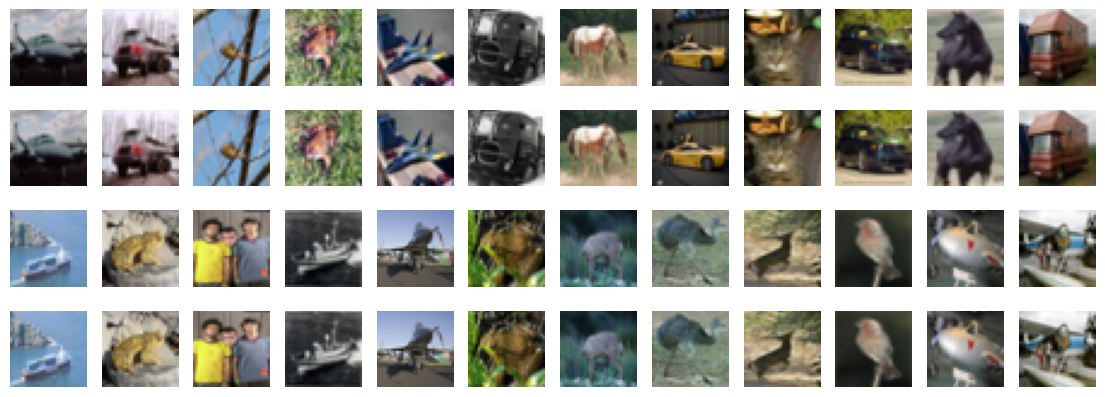

In [6]:
import matplotlib.pyplot as plt; print('train mean/std', x_all.mean((0,2,3)).tolist(), x_all.std((0,2,3)).tolist()); print('test mean/std', x_test.mean((0,2,3)).tolist(), x_test.std((0,2,3)).tolist()); pt = evaluate(model, x_test)/2; pv = evaluate(model, x_val)/2; print('conf test', pt.max(1).values.mean().item(), 'val', pv.max(1).values.mean().item()); print('test pred counts', torch.bincount(pt.argmax(1), minlength=10).tolist()); print('train label counts', torch.bincount(y_all, minlength=10).tolist()); u = lambda t: (t*std+mean).clamp(0,1).permute(0,2,3,1).cpu().numpy(); fig, ax = plt.subplots(4, 12, figsize=(14, 5)); [(ax[r, c].imshow(u((x_tr if r < 2 else x_test)[None, r*12+c if r%2==0 else (r-1)*12+c][0:1])[0]), ax[r, c].axis('off')) for r in range(4) for c in range(12)]; plt.show()

In [7]:
hf = lambda t: (t[:,:,:,1:]-t[:,:,:,:-1]).abs().mean().item(); print('hf train', hf(x_all), 'test', hf(x_test)); print('chan mean train', x_all.mean((0,2,3)).tolist(), 'test', x_test.mean((0,2,3)).tolist()); print('per-img std train', x_all.std((1,2,3)).mean().item(), 'test', x_test.std((1,2,3)).mean().item()); print('per-img mean abs train', x_all.mean((1,2,3)).abs().mean().item(), 'test', x_test.mean((1,2,3)).abs().mean().item()); print('min/max', x_all.min().item(), x_all.max().item(), x_test.min().item(), x_test.max().item())

hf train 0.21577489376068115 test 0.23402664065361023
chan mean train [1.2695312534560799e-07, 4.394531316620487e-08, 1.2336730037532107e-07] test [0.08728548139333725, 0.06423433125019073, 0.05616992339491844]
per-img std train 0.837178111076355 test 0.8716000914573669
per-img mean abs train 0.3893362283706665 test 0.4454041123390198
min/max -1.9892128705978394 2.1267893314361572 -1.9892128705978394 2.1267893314361572


In [8]:
exec("def aug3(xb):\n    n = xb.shape[0]\n    flip = torch.rand(n, device=dev) < 0.5\n    xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)\n    padded = F.pad(xb, (4, 4, 4, 4), mode='reflect')\n    oy = torch.randint(0, 9, (n,), device=dev)\n    ox = torch.randint(0, 9, (n,), device=dev)\n    ar = torch.arange(32, device=dev)\n    rows = (oy[:, None] + ar[None])[:, None, :, None]\n    cols = (ox[:, None] + ar[None])[:, None, None, :]\n    xb = padded[torch.arange(n, device=dev)[:, None, None, None], torch.arange(3, device=dev)[None, :, None, None], rows, cols]\n    gain = 1 + (torch.rand(n, 1, 1, 1, device=dev) - 0.5) * 0.6\n    chan = 1 + (torch.rand(n, 3, 1, 1, device=dev) - 0.5) * 0.2\n    bias = (torch.rand(n, 1, 1, 1, device=dev) - 0.5) * 0.6\n    return xb * gain * chan + bias\n\n\ndef cutmix(xb, yb):\n    lam = np.random.beta(1.0, 1.0)\n    p = torch.randperm(xb.size(0), device=dev)\n    cut = int(32 * (1 - lam) ** 0.5)\n    cy, cx = np.random.randint(32), np.random.randint(32)\n    y1, y2 = max(cy - cut // 2, 0), min(cy + cut // 2, 32)\n    x1, x2 = max(cx - cut // 2, 0), min(cx + cut // 2, 32)\n    xb = xb.clone()\n    xb[:, :, y1:y2, x1:x2] = xb[p][:, :, y1:y2, x1:x2]\n    return xb, yb, yb[p], 1 - (y2 - y1) * (x2 - x1) / 1024\n")

In [9]:
exec("def train_one(seed, epochs):\n    torch.manual_seed(seed)\n    m = ResNet(WIDTHS, BLOCKS).to(dev).to(memory_format=torch.channels_last)\n    o = torch.optim.SGD(m.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)\n    s = torch.optim.lr_scheduler.OneCycleLR(o, max_lr=0.1, total_steps=epochs * steps_per_epoch, pct_start=0.2)\n    sc = torch.cuda.amp.GradScaler()\n    for ep in range(epochs):\n        m.train()\n        order = torch.randperm(len(x_tr), device=dev)\n        for i in range(steps_per_epoch):\n            idx = order[i * BS:(i + 1) * BS]\n            xb, ya, yb2, lam = aug3(x_tr[idx]), y_tr[idx], y_tr[idx], 1.0\n            if np.random.rand() < 0.5:\n                xb, ya, yb2, lam = cutmix(xb, ya)\n            xb = xb.contiguous(memory_format=torch.channels_last)\n            with torch.autocast('cuda', dtype=torch.float16):\n                out = m(xb)\n                loss = lam * loss_fn(out, ya) + (1 - lam) * loss_fn(out, yb2)\n            o.zero_grad(set_to_none=True)\n            sc.scale(loss).backward()\n            sc.step(o)\n            sc.update()\n            s.step()\n        if ep % 10 == 9:\n            print(seed, ep + 1, evaluate(m, x_val, y_val), flush=True)\n    return evaluate(m, x_test), evaluate(m, x_val)\n")

In [10]:
exec("ens_t = probs.clone()\nens_v = evaluate(model, x_val)\nfor sd in (11, 12):\n    pt, pv = train_one(sd, 100)\n    ens_t += pt\n    ens_v += pv\n    print('model done', sd, 'ensemble val acc', (ens_v.argmax(1) == y_val).float().mean().item(), flush=True)\n    sub = pd.DataFrame({'id': test_df['id'], 'label': ens_t.argmax(1).cpu().numpy()})\n    sub.to_csv('submission_v3.csv', index=False)\nL = sub['label'].tolist()\nprint(len(L), sum(L))\nfor i in range(0, 2000, 50):\n    print(f'{i:04d}', ' '.join(''.join(map(str, L[j:j + 10])) for j in range(i, i + 50, 10)), sum(L[i:i + 50]))\n")

<string>:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.


11 10 0.8070000410079956
11 20 0.8880000710487366
11 30 0.8890000581741333
11 40 0.921500027179718
11 50 0.9050000309944153
11 60 0.9205000400543213
11 70 0.9355000257492065
11 80 0.9230000376701355
11 90 0.9565000534057617
11 100 0.9600000381469727
model done 11 ensemble val acc 0.9640000462532043
12 10 0.8010000586509705
12 20 0.8770000338554382
12 30 0.9020000696182251
12 40 0.8980000615119934
12 50 0.9075000286102295
12 60 0.9155000448226929
12 70 0.9295000433921814
12 80 0.9375000596046448
12 90 0.956000030040741
12 100 0.9630000591278076
model done 12 ensemble val acc 0.9635000228881836
2000 9074
0000 6339328488 3198567961 7862865806 4242203908 4214282687 243
0050 3327132560 4552554639 0421601596 9319960245 3624760001 191
0100 8145301041 9542887095 6337204722 2509258416 8333577148 211
0150 8369770318 2401371329 0015271039 2063888821 9028358874 212
0200 4703153392 0449240364 3425816871 7125368689 4325441952 212
0250 4258275823 1442410946 4817968693 7082778476 8369829300 246
0300 5

In [11]:
exec("def aug3(xb):\n    n = xb.shape[0]\n    flip = torch.rand(n, device=dev) < 0.5\n    xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)\n    padded = F.pad(xb, (4, 4, 4, 4), mode='reflect')\n    oy = torch.randint(0, 9, (n,), device=dev)\n    ox = torch.randint(0, 9, (n,), device=dev)\n    ar = torch.arange(32, device=dev)\n    rows = (oy[:, None] + ar[None])[:, None, :, None]\n    cols = (ox[:, None] + ar[None])[:, None, None, :]\n    xb = padded[torch.arange(n, device=dev)[:, None, None, None], torch.arange(3, device=dev)[None, :, None, None], rows, cols]\n    gain = 1 + (torch.rand(n, 1, 1, 1, device=dev) - 0.5) * 0.6\n    chan = 1 + (torch.rand(n, 3, 1, 1, device=dev) - 0.5) * 0.2\n    bias = (torch.rand(n, 1, 1, 1, device=dev) - 0.5) * 0.6\n    xb = xb * gain * chan + bias\n    g = xb.mean(1, keepdim=True)\n    xb = g + (xb - g) * (1 + (torch.rand(n, 1, 1, 1, device=dev) - 0.5))\n    k = (torch.tensor([[1., 2., 1.], [2., 4., 2.], [1., 2., 1.]], device=dev) / 16)[None, None].repeat(3, 1, 1, 1)\n    bl = F.conv2d(F.pad(xb, (1, 1, 1, 1), mode='reflect'), k, groups=3)\n    xb = xb + (torch.rand(n, 1, 1, 1, device=dev) * 2.5 - 1.0) * (xb - bl)\n    return xb + torch.randn_like(xb) * torch.rand(n, 1, 1, 1, device=dev) * 0.2\n")

In [12]:
exec("WIDTHS = (42, 84, 168, 336)\nprint(sum(p.numel() for p in ResNet(WIDTHS, BLOCKS).parameters() if p.requires_grad))\npt4, pv4 = train_one(21, 150)\nsub4 = pd.DataFrame({'id': test_df['id'], 'label': pt4.argmax(1).cpu().numpy()})\nsub4.to_csv('submission_v4.csv', index=False)\nL = sub4['label'].tolist()\nprint(len(L), sum(L), (pv4.argmax(1) == y_val).float().mean().item())\nfor i in range(0, 2000, 50):\n    print(f'{i:04d}', ' '.join(''.join(map(str, L[j:j + 10])) for j in range(i, i + 50, 10)), sum(L[i:i + 50]))\n")

4815940


<string>:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.


21 10 0.8260000348091125
21 20 0.8295000195503235
21 30 0.8495000600814819
21 40 0.8950000405311584
21 50 0.9140000343322754
21 60 0.878000020980835
21 70 0.9025000333786011
21 80 0.9180000424385071
21 90 0.9140000343322754
21 100 0.9150000214576721
21 110 0.9340000152587891
21 120 0.936500072479248
21 130 0.955500066280365
21 140 0.9565000534057617
21 150 0.9655000567436218
2000 8987 0.9655000567436218
0000 6339328408 3198567961 7822865806 4242203908 4214282687 231
0050 3367172560 4552254639 0421601596 9319960243 3624760001 194
0100 8105301041 9545887895 6337204767 2509258416 8333577148 227
0150 8369772318 2401371329 0095271029 2063888821 9028330874 211
0200 5403153302 0449230363 3425816879 0125538689 4725441952 203
0250 4258275823 1442410946 4817968293 7082778476 8369829300 242
0300 5769256916 4930252812 5531218318 5313539533 1970887875 229
0350 0110819387 3465726436 3536343758 6831520873 4783024912 214
0400 1045859149 1371476914 5383516393 4394306099 8950376662 234
0450 1108782328 4

In [1]:
from pathlib import Path
import shutil
from datetime import datetime
run_dir = Path('/kaggle/working') / ('wrn_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
run_dir.mkdir(exist_ok=False)
for path in Path('/kaggle/working').glob('*'):
    if path.is_file():
        shutil.copy2(path, run_dir / path.name)
torch.save(model.state_dict(), run_dir / 'baseline_in_memory.pt')
print('Preserved files:', [p.name for p in run_dir.iterdir()])
print('GPU:', torch.cuda.get_device_name(), 'available GB:', torch.cuda.mem_get_info()[0] / 1e9)
print('Baseline validation:', evaluate(model, x_val, y_val))
print('Split sizes:', len(x_tr), len(x_val))
print('Model:', model)


NameError: name 'torch' is not defined

In [2]:
import torch
from pathlib import Path
print('GPU:', torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0), torch.cuda.device_count())
print('Existing files:', [(str(p), p.stat().st_size) for p in Path('/kaggle/working').rglob('*') if p.is_file()])


GPU: True
Tesla T4 2
Existing files: [('/kaggle/working/.virtual_documents/__notebook_source__.ipynb', 13770)]


In [3]:
import os
import math
import time
import json
import random
import copy
import shutil
from pathlib import Path
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split

SEED = 42
EPOCHS = 200
BATCH_SIZE = 256
device = torch.device('cuda')
assert torch.cuda.is_available()
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
torch.set_num_threads(4)

data_root = next(Path('/kaggle/input').rglob('train_labels.csv')).parent
experiment_dir = Path('/kaggle/working') / ('wrn28_56_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
experiment_dir.mkdir(exist_ok=False)
source_path = Path('/kaggle/working/.virtual_documents/__notebook_source__.ipynb')
if source_path.exists():
    shutil.copy2(source_path, experiment_dir / 'notebook_before_training.ipynb')
train_frame = pd.read_csv(data_root / 'train_labels.csv')
test_frame = pd.read_csv(data_root / 'test.csv')
sample_frame = pd.read_csv(data_root / 'sample_submission.csv')
assert len(train_frame) == 50000
assert len(test_frame) == len(sample_frame) == 2000
assert list(sample_frame.columns) == ['id', 'label']
assert sample_frame.id.equals(test_frame.id)
assert train_frame.label.between(0, 9).all()
train_indices, valid_indices = train_test_split(
    np.arange(len(train_frame)), test_size=5000,
    random_state=SEED, stratify=train_frame.label
)
np.savez(experiment_dir / 'split.npz', train=train_indices, valid=valid_indices)

def read_training_image(filename):
    with Image.open(data_root / 'train_images' / filename) as image:
        return np.array(image.convert('RGB'))

with ThreadPoolExecutor(max_workers=16) as pool:
    train_images = np.stack(list(pool.map(read_training_image, train_frame.filename)))
train_mean = train_images[train_indices].mean((0, 1, 2)) / 255
train_std = train_images[train_indices].std((0, 1, 2)) / 255
normal_mean = torch.tensor(train_mean, dtype=torch.float32, device=device)[None, :, None, None]
normal_std = torch.tensor(train_std, dtype=torch.float32, device=device)[None, :, None, None]
all_images = torch.from_numpy(train_images).to(device).permute(0, 3, 1, 2).contiguous()
all_labels = torch.tensor(train_frame.label.values, dtype=torch.long, device=device)
train_ids = torch.tensor(train_indices, device=device)
valid_ids = torch.tensor(valid_indices, device=device)
del train_images

class WideResidualBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(cin)
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.projection = None if cin == cout and stride == 1 else nn.Conv2d(cin, cout, 1, stride, bias=False)

    def forward(self, x):
        h = F.relu(self.bn1(x))
        shortcut = x if self.projection is None else self.projection(h)
        h = self.conv1(h)
        h = self.conv2(F.dropout(F.relu(self.bn2(h)), p=0.1, training=self.training))
        return h + shortcut

class WideResNet28(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Conv2d(3, 16, 3, 1, 1, bias=False)
        layers = []
        cin = 16
        for stage, cout in enumerate((56, 112, 224)):
            for block in range(4):
                layers.append(WideResidualBlock(cin, cout, 2 if stage > 0 and block == 0 else 1))
                cin = cout
        self.blocks = nn.Sequential(*layers)
        self.bn = nn.BatchNorm2d(cin)
        self.fc = nn.Linear(cin, 10)
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(layer, nn.BatchNorm2d):
                nn.init.ones_(layer.weight)
                nn.init.zeros_(layer.bias)
        nn.init.zeros_(self.fc.bias)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        x = F.adaptive_avg_pool2d(F.relu(self.bn(x)), 1).flatten(1)
        return self.fc(x)

network = WideResNet28().to(device).to(memory_format=torch.channels_last)
parameter_count = sum(p.numel() for p in network.parameters() if p.requires_grad)
assert parameter_count <= 5_000_000, parameter_count
average_network = copy.deepcopy(network).eval()
average_network.requires_grad_(False)
config = dict(seed=SEED, epochs=EPOCHS, batch_size=BATCH_SIZE,
              channels=[56, 112, 224], blocks_per_stage=4,
              parameters=parameter_count, train_mean=train_mean.tolist(),
              train_std=train_std.tolist(), validation_size=5000,
              optimizer='SGD', learning_rate=0.1, weight_decay=0.0005,
              momentum=0.9, ema_decay=0.995,
              mixup_alpha=0.2, cutmix_alpha=1.0, clean_final_epochs=15,
              pretrained=False, external_training_data=False)
(experiment_dir / 'config.json').write_text(json.dumps(config, indent=2))
references = """Architecture: Zagoruyko and Komodakis, Wide Residual Networks (2016), https://arxiv.org/abs/1605.07146
Mixup: Zhang et al., mixup: Beyond Empirical Risk Minimization (2018), https://arxiv.org/abs/1710.09412
CutMix: Yun et al., CutMix (2019), https://arxiv.org/abs/1905.04899
Implementation uses PyTorch; no external weights or datasets are loaded.
"""
(experiment_dir / 'references.txt').write_text(references)
print('GPU:', torch.cuda.get_device_name(0), flush=True)
print('Trainable parameters:', parameter_count, flush=True)
print('Training / validation:', len(train_ids), len(valid_ids), flush=True)
print('Output:', experiment_dir, flush=True)


GPU: Tesla T4
Trainable parameters: 4480474
Training / validation: 45000 5000
Output: /kaggle/working/wrn28_56_20261104_155327


In [4]:
def normalize_images(images):
    return (images.float().div(255) - normal_mean) / normal_std

def training_augmentation(images):
    images = images.float().div(255)
    n = len(images)
    images = torch.where(torch.rand(n, 1, 1, 1, device=device) < 0.5, images.flip(3), images)
    padded = F.pad(images, (4, 4, 4, 4), mode='reflect')
    offsets = torch.randint(0, 9, (n, 2), device=device)
    positions = torch.arange(32, device=device)
    rows = (offsets[:, 0, None] + positions)[..., None]
    cols = (offsets[:, 1, None] + positions)[:, None, :]
    images = padded[torch.arange(n, device=device)[:, None, None, None],
                    torch.arange(3, device=device)[None, :, None, None],
                    rows[:, None], cols[:, None]]
    brightness = 1 + (torch.rand(n, 1, 1, 1, device=device) - 0.5) * 0.4
    contrast = 1 + (torch.rand(n, 1, 1, 1, device=device) - 0.5) * 0.4
    saturation = 1 + (torch.rand(n, 1, 1, 1, device=device) - 0.5) * 0.4
    images = images * brightness
    center = images.mean((1, 2, 3), keepdim=True)
    images = (images - center) * contrast + center
    gray = (images * images.new_tensor([0.299, 0.587, 0.114])[None, :, None, None]).sum(1, keepdim=True)
    images = ((images - gray) * saturation + gray).clamp(0, 1)
    return ((images - normal_mean) / normal_std).contiguous(memory_format=torch.channels_last)

def mix_training_batch(images, labels, epoch):
    if epoch >= EPOCHS - 15:
        return images, labels, labels, 1.0
    choice = np.random.rand()
    order = torch.randperm(len(images), device=device)
    if choice < 0.5:
        lam = np.random.beta(1.0, 1.0)
        size = int(32 * math.sqrt(1 - lam))
        cx, cy = np.random.randint(32, size=2)
        left, right = max(0, cx - size // 2), min(32, cx + size // 2)
        top, bottom = max(0, cy - size // 2), min(32, cy + size // 2)
        images[:, :, top:bottom, left:right] = images[order, :, top:bottom, left:right]
        lam = 1 - (right - left) * (bottom - top) / 1024
        return images, labels, labels[order], lam
    if choice < 0.7:
        lam = np.random.beta(0.2, 0.2)
        return images * lam + images[order] * (1 - lam), labels, labels[order], lam
    return images, labels, labels, 1.0

@torch.no_grad()
def validation_predictions(net):
    net.eval()
    results = []
    for ids in valid_ids.split(256):
        images = normalize_images(all_images[ids]).contiguous(memory_format=torch.channels_last)
        with torch.autocast('cuda', dtype=torch.float16):
            probabilities = (net(images).float().softmax(1) + net(images.flip(3)).float().softmax(1)) / 2
        results.append(probabilities)
    probabilities = torch.cat(results)
    accuracy = (probabilities.argmax(1) == all_labels[valid_ids]).float().mean().item()
    return accuracy, probabilities

optimizer = torch.optim.SGD(network.parameters(), lr=0.1, momentum=0.9,
                            nesterov=True, weight_decay=5e-4)
steps_per_epoch = math.ceil(len(train_ids) / BATCH_SIZE)
def lr_multiplier(step):
    epoch_fraction = step / steps_per_epoch
    if epoch_fraction < 5:
        return 0.1 + 0.9 * epoch_fraction / 5
    progress = (epoch_fraction - 5) / (EPOCHS - 5)
    return 0.001 + 0.999 * (1 + math.cos(math.pi * progress)) / 2

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_multiplier)
scaler = torch.amp.GradScaler('cuda')
loss_function = nn.CrossEntropyLoss(label_smoothing=0.0)
history = []
best_accuracy = -1.0
training_started = time.time()
probe = training_augmentation(all_images[train_ids[:8]])
assert probe.shape == (8, 3, 32, 32)
assert network(probe).shape == (8, 10)
assert torch.isfinite(probe).all()
print('Data and model checks passed. Training from scratch.', flush=True)

for epoch in range(EPOCHS):
    epoch_started = time.time()
    network.train()
    order = train_ids[torch.randperm(len(train_ids), device=device)]
    loss_total = 0.0
    for ids in order.split(BATCH_SIZE):
        images = training_augmentation(all_images[ids])
        images, labels_a, labels_b, lam = mix_training_batch(images, all_labels[ids], epoch)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            logits = network(images)
            loss = lam * loss_function(logits, labels_a) + (1 - lam) * loss_function(logits, labels_b)
        if not torch.isfinite(loss):
            raise RuntimeError('Non-finite loss; previous checkpoints are preserved.')
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        with torch.no_grad():
            torch._foreach_lerp_(list(average_network.parameters()), list(network.parameters()), 1 - 0.995)
            for average_buffer, current_buffer in zip(average_network.buffers(), network.buffers()):
                average_buffer.copy_(current_buffer)
        loss_total += loss.item() * len(ids)

    accuracy, valid_probabilities = validation_predictions(network)
    average_accuracy, average_probabilities = validation_predictions(average_network)
    selected_network = average_network if average_accuracy > accuracy else network
    selected_accuracy = max(accuracy, average_accuracy)
    record = dict(epoch=epoch + 1, loss=loss_total / len(train_ids),
                  validation=accuracy, ema_validation=average_accuracy,
                  lr=optimizer.param_groups[0]['lr'],
                  seconds=time.time() - epoch_started)
    history.append(record)
    pd.DataFrame(history).to_csv(experiment_dir / 'history.csv', index=False)

    if selected_accuracy > best_accuracy:
        best_accuracy = selected_accuracy
        best_checkpoint = dict(model={k: v.detach().cpu() for k, v in selected_network.state_dict().items()},
                               epoch=epoch + 1, validation_accuracy=best_accuracy,
                               parameters=parameter_count, config=config,
                               selected='ema' if selected_network is average_network else 'raw')
        temporary_path = experiment_dir / 'best.tmp'
        torch.save(best_checkpoint, temporary_path)
        temporary_path.replace(experiment_dir / 'best.pt')
        np.save(experiment_dir / 'validation_probabilities.npy',
                (average_probabilities if selected_network is average_network else valid_probabilities).cpu().numpy())

    if (epoch + 1) % 10 == 0 or epoch + 1 == EPOCHS:
        torch.save(dict(model=network.state_dict(), ema=average_network.state_dict(),
                        optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                        scaler=scaler.state_dict(), epoch=epoch + 1,
                        best_accuracy=best_accuracy, history=history, config=config,
                        torch_rng=torch.get_rng_state(), cuda_rng=torch.cuda.get_rng_state_all(),
                        numpy_rng=np.random.get_state(), python_rng=random.getstate()),
                   experiment_dir / 'last.pt')
    print(f"Epoch {epoch + 1:3d}/{EPOCHS}: loss {record['loss']:.4f}, "
          f"val {accuracy:.4f}, EMA {average_accuracy:.4f}, "
          f"best {best_accuracy:.4f}, {record['seconds']:.1f}s", flush=True)

best_checkpoint = torch.load(experiment_dir / 'best.pt', map_location=device, weights_only=False)
network.load_state_dict(best_checkpoint['model'])
verified_accuracy, _ = validation_predictions(network)
assert abs(verified_accuracy - best_checkpoint['validation_accuracy']) < 1e-6
network.eval()
def read_test_image(filename):
    with Image.open(data_root / 'test_images' / filename) as image:
        return np.array(image.convert('RGB'))
with ThreadPoolExecutor(max_workers=16) as pool:
    test_images = np.stack(list(pool.map(read_test_image, test_frame.filename)))
test_probabilities = []
with torch.no_grad():
    for start in range(0, len(test_images), 256):
        images = torch.from_numpy(test_images[start:start + 256]).to(device).permute(0, 3, 1, 2)
        images = normalize_images(images).contiguous(memory_format=torch.channels_last)
        with torch.autocast('cuda', dtype=torch.float16):
            probabilities = (network(images).float().softmax(1) + network(images.flip(3)).float().softmax(1)) / 2
        test_probabilities.append(probabilities.cpu())
test_probabilities = torch.cat(test_probabilities).numpy()
np.save(experiment_dir / 'test_probabilities.npy', test_probabilities)
submission = sample_frame.copy()
submission['label'] = test_probabilities.argmax(1).astype('int64')
assert list(submission.columns) == ['id', 'label']
assert submission.id.equals(sample_frame.id)
assert submission.id.is_unique and len(submission) == 2000
assert submission.label.between(0, 9).all()
assert not submission.isna().any().any()
submission.to_csv(experiment_dir / 'submission.csv', index=False)
print('Verified validation accuracy:', verified_accuracy, flush=True)
print('Final model parameters:', parameter_count, flush=True)
print('Submission saved:', experiment_dir / 'submission.csv', flush=True)
print('Total minutes:', (time.time() - training_started) / 60, flush=True)


Data and model checks passed. Training from scratch.
Epoch   1/200: loss 1.9703, val 0.3914, EMA 0.1698, best 0.3914, 21.7s
Epoch   2/200: loss 1.6640, val 0.4830, EMA 0.3038, best 0.4830, 18.0s
Epoch   3/200: loss 1.4096, val 0.6246, EMA 0.3816, best 0.6246, 18.4s
Epoch   4/200: loss 1.3691, val 0.6688, EMA 0.5034, best 0.6688, 18.8s
Epoch   5/200: loss 1.2185, val 0.7338, EMA 0.6082, best 0.7338, 19.1s
Epoch   6/200: loss 1.1985, val 0.7408, EMA 0.5826, best 0.7408, 19.6s
Epoch   7/200: loss 1.0988, val 0.7402, EMA 0.6026, best 0.7408, 19.4s
Epoch   8/200: loss 1.0507, val 0.7486, EMA 0.5184, best 0.7486, 19.1s
Epoch   9/200: loss 1.0546, val 0.8392, EMA 0.5498, best 0.8392, 19.1s
Epoch  10/200: loss 0.9916, val 0.8082, EMA 0.7698, best 0.8392, 19.2s
Epoch  11/200: loss 1.0289, val 0.8084, EMA 0.5912, best 0.8392, 19.3s
Epoch  12/200: loss 0.9578, val 0.8490, EMA 0.5318, best 0.8490, 19.2s
Epoch  13/200: loss 1.0134, val 0.8438, EMA 0.7426, best 0.8490, 19.2s
Epoch  14/200: loss 0.95

KeyboardInterrupt: 

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

history_frame = pd.read_csv(experiment_dir / 'history.csv')
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_frame.epoch, history_frame.loss)
axes[0].set(xlabel='Epoch', ylabel='Training loss')
axes[1].plot(history_frame.epoch, history_frame.validation, label='Current weights')
axes[1].plot(history_frame.epoch, history_frame.ema_validation, label='Averaged weights')
axes[1].set(xlabel='Epoch', ylabel='Validation accuracy')
axes[1].legend()
figure.tight_layout()
figure.savefig(experiment_dir / 'training_curves.png', dpi=180)
plt.show()

validation_accuracy, validation_probabilities = validation_predictions(network)
validation_labels = all_labels[valid_ids].cpu().numpy()
validation_classes = validation_probabilities.argmax(1).cpu().numpy()
matrix = confusion_matrix(validation_labels, validation_classes, labels=np.arange(10))
pd.DataFrame(matrix).to_csv(experiment_dir / 'validation_confusion_matrix.csv', index=False)
class_accuracy = pd.DataFrame({
    'label': np.arange(10),
    'accuracy': matrix.diagonal() / matrix.sum(1)
})
class_accuracy.to_csv(experiment_dir / 'validation_class_accuracy.csv', index=False)
summary = dict(validation_accuracy=validation_accuracy,
               parameters=sum(p.numel() for p in network.parameters()),
               selected_checkpoint_epoch=best_checkpoint['epoch'],
               selected_weights=best_checkpoint['selected'],
               public_score=None, validation_seed=SEED,
               validation_size=len(valid_ids), training_size=len(train_ids))
assert summary['parameters'] <= 5_000_000
(experiment_dir / 'summary.json').write_text(json.dumps(summary, indent=2))
if source_path.exists():
    source_notebook = json.loads(source_path.read_text())
    experiment_cells = [cell for cell in source_notebook['cells']
                        if cell['cell_type'] == 'code' and
                        ('class WideResNet28' in ''.join(cell['source']) or
                         'def normalize_images' in ''.join(cell['source']))]
    if len(experiment_cells) == 2:
        for cell in experiment_cells:
            cell['outputs'] = []
            cell['execution_count'] = None
        clean_notebook = dict(cells=experiment_cells, metadata=source_notebook['metadata'],
                              nbformat=4, nbformat_minor=5)
        (experiment_dir / 'experiment.ipynb').write_text(json.dumps(clean_notebook, indent=1))
        (experiment_dir / 'train.py').write_text('\n\n'.join(''.join(c['source']) for c in experiment_cells))
print(json.dumps(summary, indent=2))
print(class_accuracy.to_string(index=False))
print('Files:', [p.name for p in experiment_dir.iterdir()])


In [5]:
best_checkpoint = torch.load(experiment_dir / 'best.pt', map_location=device, weights_only=False)
network.load_state_dict(best_checkpoint['model'])
verified_accuracy, _ = validation_predictions(network)
assert abs(verified_accuracy - best_checkpoint['validation_accuracy']) < 1e-6
network.eval()
def read_test_image(filename):
    with Image.open(data_root / 'test_images' / filename) as image:
        return np.array(image.convert('RGB'))
with ThreadPoolExecutor(max_workers=16) as pool:
    test_images = np.stack(list(pool.map(read_test_image, test_frame.filename)))
test_probabilities = []
with torch.no_grad():
    for start in range(0, len(test_images), 256):
        images = torch.from_numpy(test_images[start:start + 256]).to(device).permute(0, 3, 1, 2)
        images = normalize_images(images).contiguous(memory_format=torch.channels_last)
        with torch.autocast('cuda', dtype=torch.float16):
            probabilities = (network(images).float().softmax(1) + network(images.flip(3)).float().softmax(1)) / 2
        test_probabilities.append(probabilities.cpu())
test_probabilities = torch.cat(test_probabilities).numpy()
np.save(experiment_dir / 'test_probabilities.npy', test_probabilities)
submission = sample_frame.copy()
submission['label'] = test_probabilities.argmax(1).astype('int64')
assert list(submission.columns) == ['id', 'label']
assert submission.id.equals(sample_frame.id)
assert submission.id.is_unique and len(submission) == 2000
assert submission.label.between(0, 9).all()
assert not submission.isna().any().any()
submission.to_csv(experiment_dir / 'submission.csv', index=False)
print('Verified validation accuracy:', verified_accuracy, flush=True)
print('Final model parameters:', parameter_count, flush=True)
print('Submission saved:', experiment_dir / 'submission.csv', flush=True)
print('Total minutes:', (time.time() - training_started) / 60, flush=True)


Verified validation accuracy: 0.925599992275238
Final model parameters: 4480474
Submission saved: /kaggle/working/wrn28_56_20261104_155327/submission.csv
Total minutes: 13.127365791797638


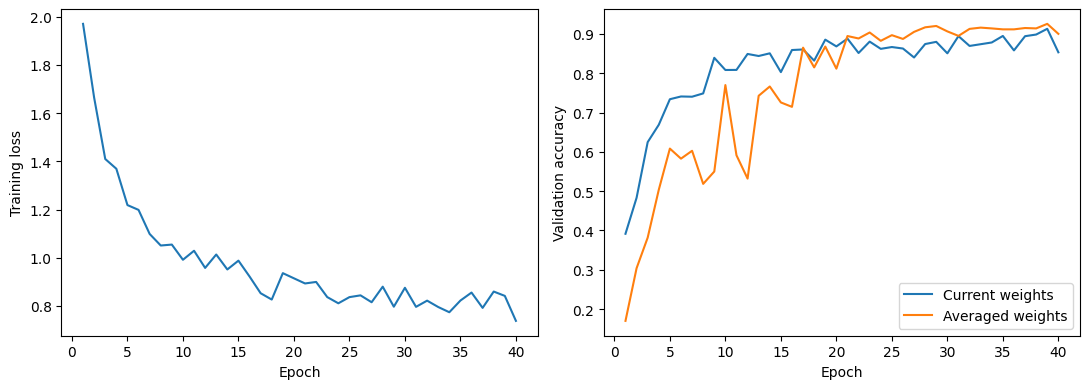

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

history_frame = pd.read_csv(experiment_dir / 'history.csv')
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_frame.epoch, history_frame.loss)
axes[0].set(xlabel='Epoch', ylabel='Training loss')
axes[1].plot(history_frame.epoch, history_frame.validation, label='Current weights')
axes[1].plot(history_frame.epoch, history_frame.ema_validation, label='Averaged weights')
axes[1].set(xlabel='Epoch', ylabel='Validation accuracy')
axes[1].legend()
figure.tight_layout()
figure.savefig(experiment_dir / 'training_curves.png', dpi=180)
plt.show()

validation_accuracy, validation_probabilities = validation_predictions(network)
validation_labels = all_labels[valid_ids].cpu().numpy()
validation_classes = validation_probabilities.argmax(1).cpu().numpy()
matrix = confusion_matrix(validation_labels, validation_classes, labels=np.arange(10))
pd.DataFrame(matrix).to_csv(experiment_dir / 'validation_confusion_matrix.csv', index=False)
class_accuracy = pd.DataFrame({
    'label': np.arange(10),
    'accuracy': matrix.diagonal() / matrix.sum(1)
})
class_accuracy.to_csv(experiment_dir / 'validation_class_accuracy.csv', index=False)
summary = dict(validation_accuracy=validation_accuracy,
               parameters=sum(p.numel() for p in network.parameters()),
               selected_checkpoint_epoch=best_checkpoint['epoch'],
               selected_weights=best_checkpoint['selected'],
               public_score=None, validation_seed=SEED,
               validation_size=len(valid_ids), training_size=len(train_ids))
assert summary['parameters'] <= 5_000_000
(experiment_dir / 'summary.json').write_text(json.dumps(summary, indent=2))
if source_path.exists():
    source_notebook = json.loads(source_path.read_text())
    experiment_cells = [cell for cell in source_notebook['cells']
                        if cell['cell_type'] == 'code' and
                        ('class WideResNet28' in ''.join(cell['source']) or
                         'def normalize_images' in ''.join(cell['source']))]
    if len(experiment_cells) == 2:
        for cell in experiment_cells:
            cell['outputs'] = []
            cell['execution_count'] = None
        clean_notebook = dict(cells=experiment_cells, metadata=source_notebook['metadata'],
                              nbformat=4, nbformat_minor=5)
        (experiment_dir / 'experiment.ipynb').write_text(json.dumps(clean_notebook, indent=1))
        (experiment_dir / 'train.py').write_text('\n\n'.join(''.join(c['source']) for c in experiment_cells))
print(json.dumps(summary, indent=2))
print(class_accuracy.to_string(index=False))
print('Files:', [p.name for p in experiment_dir.iterdir()])
